# Problem 1: Statistics from uniform samples

A worked example from [Hogg & Foreman-Mackey, *Data analysis recipes: Using Markov Chain Monte Carlo*, Problem 1](https://arxiv.org/pdf/1710.06068v1).

We start with independent draws from $U(0,1)$ to see how sampling approximates integrals. Metropolis–Hastings comes later. Only NumPy and Matplotlib are needed; both are available in the existing Python 3 kernel.

## Definitions and analytic answers

For a density $p(x)$, define the mean and central moments:
$$\mu=E[X]=\int x p(x)\,dx,\qquad \mu_r=E[(X-\mu)^r]=\int(x-\mu)^r p(x)\,dx.$$
Variance measures spread, skewness measures asymmetry, and kurtosis measures the standardized fourth moment (sensitivity to large deviations from the mean):
$$\mathrm{Var}(X)=\mu_2,\qquad \mathrm{skewness}=\frac{\mu_3}{\mu_2^{3/2}},\qquad \mathrm{kurtosis}=\frac{\mu_4}{\mu_2^2}.$$

For $U(0,1)$, the density is 1 inside the interval and zero elsewhere:
$$\mu=\int_0^1x\,dx=\frac12.$$
Substitute $u=x-1/2$ to compute the central moments:
$$\mu_2=\int_{-1/2}^{1/2}u^2\,du=\left[\frac{u^3}{3}\right]_{-1/2}^{1/2}=\frac1{12},$$
$$\mu_3=\int_{-1/2}^{1/2}u^3\,du=0\quad\text{(odd integrand)},$$
$$\mu_4=\int_{-1/2}^{1/2}u^4\,du=\left[\frac{u^5}{5}\right]_{-1/2}^{1/2}=\frac1{80}.$$

| Statistic | Analytic value |
| --- | --- |
| Mean | $1/2$ |
| Variance | $1/12$ |
| Skewness | $0$ |
| Kurtosis | $(1/80)/(1/12)^2=9/5$ |

**Excess kurtosis** subtracts 3, giving $-6/5$ here. A normal distribution has kurtosis 3 and excess kurtosis 0. We plot ordinary kurtosis.

## Replace expectations with sample averages

For each $K$, draw a fresh sample and compute
$$\bar x=\frac1K\sum_{i=1}^Kx_i,\qquad m_r=\frac1K\sum_{i=1}^K(x_i-\bar x)^r.$$
The four estimates are $\bar x$, $m_2$, $m_3/m_2^{3/2}$, and $m_4/m_2^2$. All averages divide by $K$, without finite-sample bias corrections. The variance estimate therefore differs from the unbiased estimate that divides by $K-1$.

The fixed seed makes this reproducible. NumPy samples $[0,1)$; endpoint conventions do not change the analytic moments of a continuous uniform distribution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
Ks = 4 ** np.arange(1, 11)
estimates = []
for K in Ks:
    x = rng.uniform(0, 1, K)
    centered = x - x.mean()
    m2, m3, m4 = [np.mean(centered ** r) for r in (2, 3, 4)]
    estimates.append([x.mean(), m2, m3 / m2 ** 1.5, m4 / m2 ** 2])
estimates = np.array(estimates)

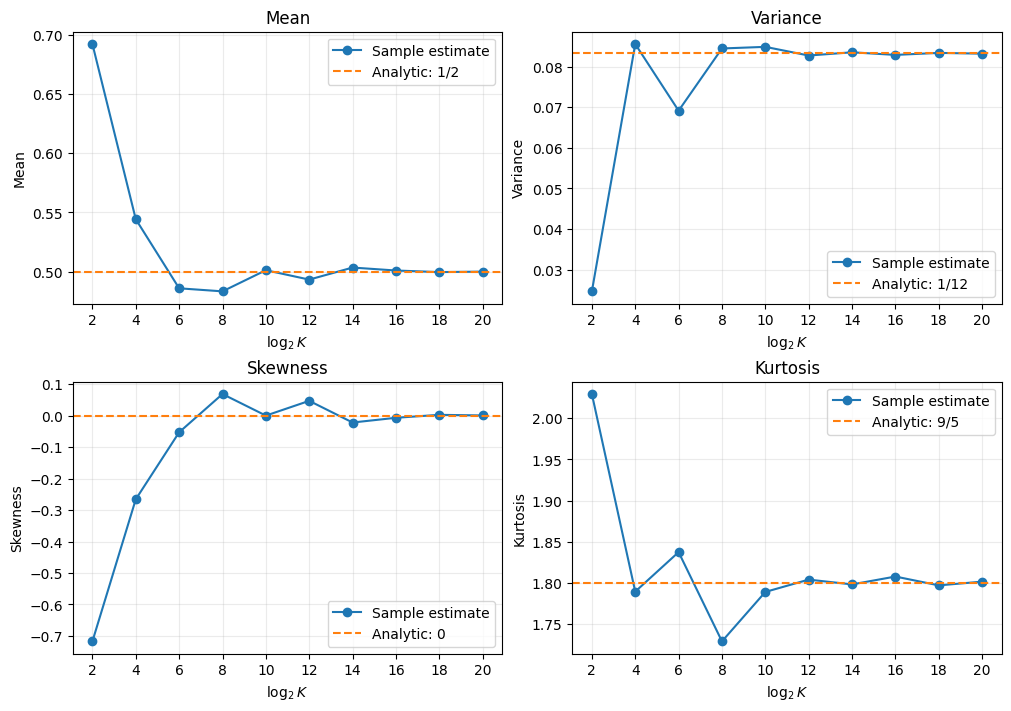

In [2]:
names = ["Mean", "Variance", "Skewness", "Kurtosis"]
truth = [1/2, 1/12, 0, 9/5]
labels = ["1/2", "1/12", "0", "9/5"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
for ax, values, name, exact, label in zip(axes.flat, estimates.T, names, truth, labels):
    ax.plot(np.log2(Ks), values, "o-", label="Sample estimate")
    ax.axhline(exact, color="tab:orange", linestyle="--", label=f"Analytic: {label}")
    ax.set(title=name, xlabel=r"$\log_2 K$", ylabel=name, xticks=np.log2(Ks))
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## What can we conclude?

As $K$ increases from 4 to 1,048,576, the estimates settle near the analytic reference lines. Small samples can give misleading descriptions of the distribution. The estimates fluctuate, so a larger sample need not produce a closer answer at every step.

For independent samples, the sample mean has standard error
$$\mathrm{SE}(\bar x)=\frac{\sigma}{\sqrt K}=\frac1{\sqrt{12K}}.$$
The other moment estimates also have typical asymptotic errors proportional to $K^{-1/2}$ here, although their constants differ and they can be biased at small $K$. Multiplying the sample size by four roughly halves typical error. This is an ensemble statement; one seeded realization does not establish that rate.

Sampling turns integrals into averages. Later, MCMC will provide samples when independent draws are difficult, and correlation between successive draws will affect their precision. To explore the fluctuations here, change the seed and rerun both code cells.